# ДЗ Введение в статистику

Выполнил: Тюрин Данил

На лекции Вы говорили что одностронний тест почти нигде не используется, поэтому я использовал везде двусторонний, хотя в условиях это не сказано.

### Задание 1

 Дано:
- $\mu_0 = 120$ с
- $n = 100$
- $\bar{x} = 124$ с
- $\sigma = 25$ с

Беру стандартные значения $\alpha = 0.05$ и $\beta = 0.2$

Гипотезы:

- $H_0: \mu = 120$
- $H_1: \mu \neq 120$



Так как генеральное σ известно, используем обычный z-test:

$$z = \frac{\bar{x} - \mu_0}{\sigma / \sqrt{n}} = \frac{\bar{x} - \mu_0}{SE(\bar{x})}$$

In [1]:
import numpy as np
from scipy.stats import norm, t

u0 = 120
n = 100
x = 124
sigma = 25
alpha = 0.05

z_test = (x - u0) / (sigma / np.sqrt(n))
p_value = 2 * norm.sf(abs(z_test))

print(f"z = {z_test}, p-value = {p_value}")

z = 1.6, p-value = 0.10959858339911595


Оценка ушла от 120 на 1,6 стандартной ошибки.

p-value больше чем альфа (0.1095 > 0.05), поэтому оснований отвергать $H_0$ нет

### Задание 2

 Дано:
- Первая группа: $n_1 = 40$; $\bar{x}_1 = 50$; $s_1 = 10$
- Вторая группа: $n_2 = 40$; $\bar{x}_2 = 55$; $s_2 = 10$


Беру стандартные значения $\alpha = 0.05$ и $\beta = 0.2$

Доверительный интервал для разницы средних $\Delta = \mu_2 - \mu_1$:

$$\hat{\Delta} \pm t_{1-\alpha/2,\,\nu} \cdot SE(\hat{\Delta})$$

Дисперсии групп равными не считаем, поэтому $SE$ и степени свободы $\nu$ считаем по Уэлчу:
$$SE(\hat{\Delta}) = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$


In [2]:
n1, x1, s1 = 40, 50, 10
n2, x2, s2 = 40, 55, 10
alpha = 0.05

diff = x2 - x1
v1, v2 = s1**2 / n1, s2**2 / n2
se = np.sqrt(v1 + v2)
df = (v1 + v2)**2 / (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))
t_crit = t.ppf(1 - alpha / 2, df)

lower_bound = diff - t_crit * se
high_bound = diff + t_crit * se

print(f"разница средних = {diff}")
print(f" Cl = [{lower_bound:.2f}, {high_bound:.2f}]")

разница средних = 5
 Cl = [0.55, 9.45]


Разница средних $\hat{\Delta} = 5$, 95% доверительный интервал [0.55; 9.45]

0 не попадает в интервал. Самый маленький эффект, который ещё согласуется с данными - 0.55

### Задание 3

Дано:

- Первая группа: $x_1 = 90$ откликов, $n_1 = 1000$ показов
- Вторая группа: $x_2 = 120$ откликов, $n_2 = 1000$ показов

Беру стандартное значение $\alpha = 0.05$

Гипотезы:

- $H_0: p_1 = p_2$ конверсии в отклик в двух группах равны
- $H_1: p_1 \neq p_2$ конверсии различаются


Использую z-test, так как конверсия - это бинарная метрика:

$$z = \frac{\hat{p}_2 - \hat{p}_1}{\sqrt{\hat{p}(1 - \hat{p})\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}, \qquad \hat{p} = \frac{x_1 + x_2}{n_1 + n_2}$$

In [3]:
x1, n1 = 90, 1000
x2, n2 = 120, 1000

p1 = x1 / n1
p2 = x2 / n2
p = (x1 + x2) / (n1 + n2)

diff_pp = (p2 - p1) * 100
z_stat = (p2 - p1) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
p_value = 2 * norm.sf(abs(z_stat))

print(f"p1 = {p1}, p2 = {p2}, p = {p}")
print(f"разница = {diff_pp:.1f} п.п.")
print(f"z = {z_stat:.2f}, p-value = {p_value:.4f}")

p1 = 0.09, p2 = 0.12, p = 0.105
разница = 3.0 п.п.
z = 2.19, p-value = 0.0287


Разница конверсий в 3 п.п. Статистика критерия z = 2.19, p-value = 0.0287

Есть основания отвергнуть $H_0$, так как p-value меньше чем альфа: 0.0287 < 0.05

### Задание 4


Я взял число 7

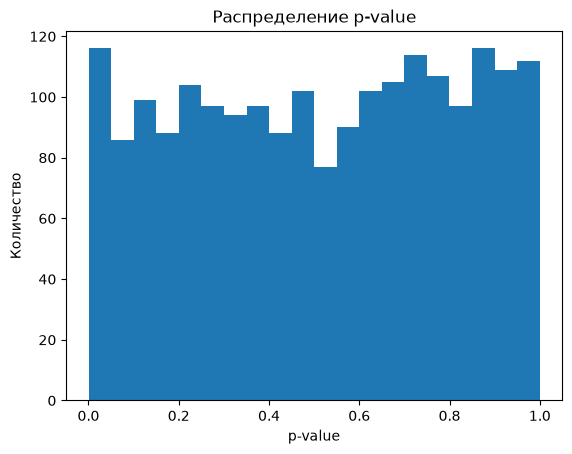

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

rng = np.random.default_rng(7)

number_of_examples = 2000
n = 200
p_values = []

for _ in range(number_of_examples):
    control = rng.normal(0, 1, size=n)
    test = rng.normal(0, 1, size=n)
    result = ttest_ind(control, test, equal_var=False, alternative="two-sided")
    p_values.append(result.pvalue)

plt.hist(p_values, bins=20)
plt.xlabel("p-value")
plt.ylabel("Количество")
plt.title("Распределение p-value")
plt.show()


По графику видно, что p-value распределены равномерно. Так получается, потому что обе группы набраны из одного и того же распределения, то есть эффекта нет и H₀ верна. Как говорилось на лекции, в таком случае любое значение p-value от 0 до 1 одинаково вероятно.

### Задание 5

In [5]:
from scipy.stats import mannwhitneyu
number_of_examples = 1000
first_group_n = 60
second_group_n = 60

mean_differences = []
welch_t = []
welch_p_values = []
mann_whitney_u = []
mann_whitney_p_values = []

for _ in range(number_of_examples):
    first = rng.normal(0, 1, size=first_group_n)
    second = rng.normal(1, 1, size=second_group_n)
    second[:2] = -50
    mean_differences.append(second.mean() - first.mean())


    welch_result = ttest_ind(first, second, equal_var=False)
    welch_t.append(welch_result.statistic)
    welch_p_values.append(welch_result.pvalue)

    mw_result = mannwhitneyu(first, second)
    mann_whitney_u.append(mw_result.statistic)
    mann_whitney_p_values.append(mw_result.pvalue)


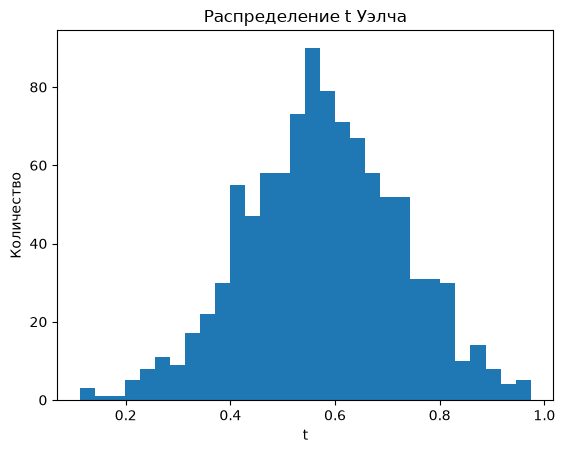

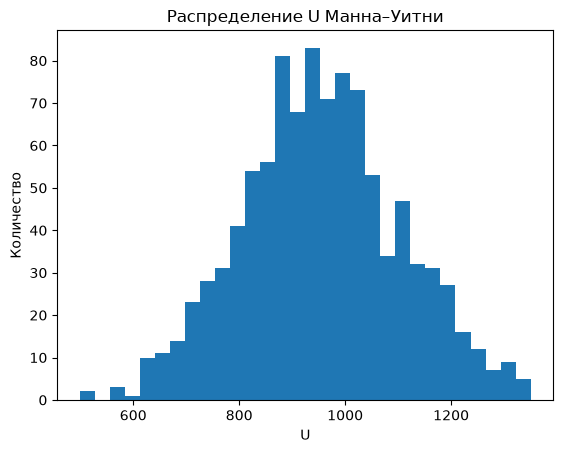

In [6]:
plt.hist(welch_t, bins=30)
plt.xlabel("t")
plt.ylabel("Количество")
plt.title("Распределение t Уэлча")
plt.show()

plt.hist(mann_whitney_u, bins=30)
plt.xlabel("U")
plt.ylabel("Количество")
plt.title("Распределение U Манна–Уитни")
plt.show()

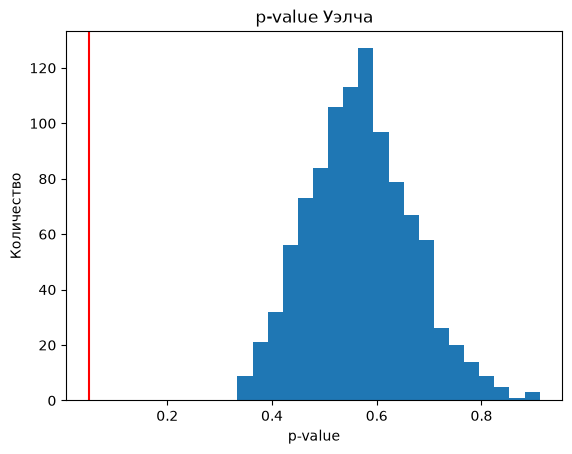

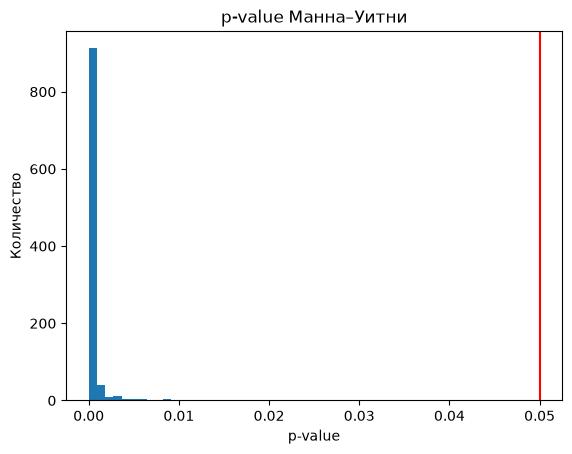

In [7]:
plt.hist(welch_p_values, bins=20)
plt.axvline(0.05, color="red")
plt.xlabel("p-value")
plt.ylabel("Количество")
plt.title("p-value Уэлча")
plt.show()

plt.hist(mann_whitney_p_values, bins=20)
plt.axvline(0.05, color="red")
plt.xlabel("p-value")
plt.ylabel("Количество")
plt.title("p-value Манна–Уитни")
plt.show()

По графикам видно, что p-value у Уэлча сосредоточены справа от 0.05, примерно от 0.3 до 1. А у Манна–Уитни почти все p-value прижаты к нулю, левее 0.05.

При двустороннем пороге 5% Уэлч ни разу не отверг $H_0$, то есть разницы нет. Манна–Уитни наоборот отверг $H_0$ во всех экспериментах, то есть разница есть.

Выводы разошлись.

Так произошло из-за двух выбросов -50. Они сильно тянут среднее второй группы вниз, поэтому разница средних получилась примерно −0.69, хотя на самом деле вторая группа больше на 1. Ещё выбросы сильно увеличивают разброс, из-за этого стандартная ошибка большая, t маленький и Уэлч эффект не замечает.


### Задание 6

In [8]:
rng = np.random.default_rng(7)

first = rng.normal(10, 2, size=80)
second = rng.normal(10.8, 2.6, size=75)

result = ttest_ind(second, first, equal_var=False)
ci = result.confidence_interval(confidence_level=0.95)

print(f"разница средних = {second.mean() - first.mean():.3f}")
print(f"p-value = {result.pvalue:.4f}")
print(f"cl = [{ci.low:.3f}, {ci.high:.3f}]")

разница средних = 0.757
p-value = 0.0225
cl = [0.109, 1.404]


p-value меньше чем альфа: 0.0225 < 0.05. Поэтому есть основания отвергнуть $H_0$.

0 не попадает в интервал. Самый маленький эффект, который ещё согласуется с данными - 0,109

### Задание 7

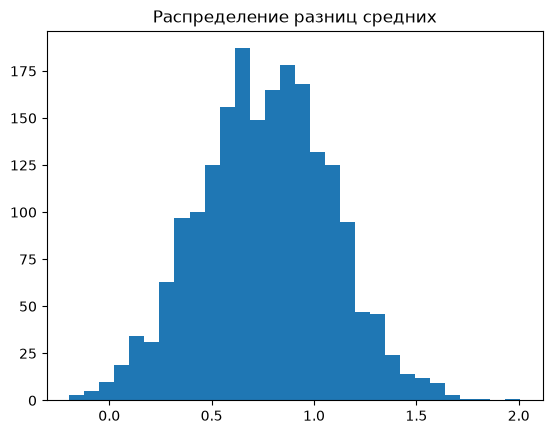

CI бутстрапа: [0.13443937 1.37831016]
Доля разниц <= 0: 0.0085


In [10]:
bootstrap_differences = []

for _ in range(2000):
    first_sample = rng.choice(first, size=80, replace=True)
    second_sample = rng.choice(second, size=75, replace=True)
    bootstrap_differences.append(second_sample.mean() - first_sample.mean())

bootstrap_differences = np.array(bootstrap_differences)

plt.hist(bootstrap_differences, bins=30)
plt.title("Распределение разниц средних")
plt.show()

print("CI бутстрапа:", np.percentile(bootstrap_differences, [2.5, 97.5]))
print("Доля разниц <= 0:", np.mean(bootstrap_differences <= 0))

95% интервал бутстрапа [0.111; 1.403], а интервал Уэлча из задачи 6 [0.109; 1.404]. Получается, что границы почти совпали.

Доля разниц, которые получились не больше нуля 0.009

Назвать её p-value нельзя. p-value считается при условии, что $H_0$ верна, то есть распределение должно быть с центром в 0. А бутстрап-распределение построено вокруг наблюдаемой разницы, в нашем случае это 0.76. Плюс эта доля считает только одну сторону, а проверка у нас двусторонняя.